# How the parametric module works

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/marc272/crc-docs/blob/parametric/notebooks/parametric_insurance_module.ipynb)

The [primer](parametric_insurance_primer.ipynb) showed what a parametric cover is:
a function from a measured index to money, with basis risk as the price of a fast
payout. This notebook shows how the parametric module of
[crc-sdk](https://github.com/RiskThinking/crc-sdk) does the work, on the primer's
imaginary brewery: one plan from start to finish, its pieces, three design goals,
honest testing, your own years and the functions underneath.

On Colab choose **Runtime → Run all**; no account needed. The first run installs
crc-sdk and downloads one small CRC Open file, in a minute or two.

## Setup

In [1]:
#@title Install packages (Colab)
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None

# crc_sdk.parametric is not in a crc-sdk release yet: install it from its development branch.
CRC_SDK = "crc-sdk[geometry,parametric] @ git+https://github.com/marc272/crc-sdk@parametric"


def has_parametric():
    spec = importlib.util.find_spec("crc_sdk")
    return spec is not None and spec.origin is not None and (Path(spec.origin).parent / "parametric").is_dir()


def pip_install(*arguments):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--disable-pip-version-check", *arguments])


if IN_COLAB or not has_parametric():
    if importlib.util.find_spec("pip") is None:  # a bare virtual environment
        subprocess.check_call([sys.executable, "-m", "ensurepip", "--upgrade"], stdout=subprocess.DEVNULL)
    pip_install(CRC_SDK, "plotly>=6,<7", "pandas>=2.2")
    if not has_parametric():  # a crc-sdk release of the same version number was already installed
        pip_install("--force-reinstall", "--no-deps", CRC_SDK)
    importlib.invalidate_caches()

# Small, quick runs for continuous integration; the same code runs either way.
CI = os.environ.get("CRC_DOCS_CI") == "1"

In [2]:
import warnings

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
from IPython.display import display

import highspy
from crc_sdk.impacts import ImpactCalibration, ImpactExpression
from crc_sdk.parametric import (
    MSE, AnnualSeries, Budget, ComonotoneIndexWarning, Cover, ExpectedUncovered, Free, FreshDraws, HazardNoise,
    IndexDefinition, Limit, LinearPayout, LossModel, MetricOptions, NoBasisRisk, OutcomeSample, ParametricPlan,
    PiecewiseLinearPayout, WeightedCVaR, compare, design, evaluate, holdout, sample_annual, sample_curve, setup_text,
    write_comparison,
)
from crc_sdk.workflows import HazardDataset
from crc_sdk.workflows.distributions import ReturnPeriodExtrapolationWarning

# About 1 simulated year in 1,000 falls outside the return periods the curve was fitted on
# (1.001 to 1,000 years), where it is extrapolated. The setup text counts them; we silence the warning.
warnings.simplefilter("ignore", ReturnPeriodExtrapolationWarning)

# The solver, HiGHS, prints its banner once, when first started: here, rather than among the results.
highspy.Highs()

# Interactive charts when you run it; saved images so GitHub can show them too.
STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = (
    "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
)
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000

DATA = Path("data") / "parametric_module"
DATA.mkdir(parents=True, exist_ok=True)

# One colour per design goal; the loss is the dotted ink line, a cover given as is the dashed grey one.
INK, BLUE, AQUA, YELLOW, MUTED = "#52514e", "#2a78d6", "#1baf7a", "#eda100", "#8a8880"
FONT = dict(family="Inter, Helvetica, Arial, sans-serif", size=14)


def layout(fig, title, setup, height=500, bottom=70, top=120, **kwargs):
    """Style a chart and state its setup under the title, so the numbers never lose it."""
    fig.update_layout(title=dict(text=title, x=0.01, y=0.97, yanchor="top",
                                 subtitle=dict(text=setup, font=dict(size=11, color=MUTED))),
                      font=FONT, height=height, margin=dict(l=75, r=30, t=top, b=bottom), hoverlabel=dict(font_size=13), **kwargs)
    return fig


COLUMNS = {"premium_basis": "Premium basis", "premium": "Premium (CAD)", "expected_loss": "Expected loss (CAD)",
           "coverage_ratio": "Expected loss covered", "tail_coverage_b0_9": "Loss covered, worst 10% of years",
           "false_negative_rate_l0": "Loss years with no payout", "false_positive_rate_l0": "No-loss years with a payout"}


def show(frame, columns=COLUMNS):
    """A comparison's rows as a table: amounts in CAD, shares in percent."""
    if isinstance(frame, pa.Table):
        frame = frame.to_pandas().set_index("cover_label")
    frame = frame[list(columns)].rename(columns=columns)
    display(frame.style.format({name: "{:,.0f}" if "CAD" in name else "{:.1%}"
                                for name in frame.columns if name != "Premium basis"}))

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


**The example.** Wet Basement Brewing is the primer's imaginary Toronto brewery,
with a stated value of CAD 5 million and a hypothetical damage curve. The rain is
CRC Open's `rx1day`, the wettest day of the year, on the hexagon around the site,
under SSP5-8.5 in 2030. CRC Open has no historical baseline, so every simulated
year describes that future.

In [3]:
RELEASE, PATHWAY, HORIZON = "ssp585-global-2026-10-20-v1", "ssp585", 2030
ASSET = {"asset_id": "Wet Basement Brewing", "longitude": -79.38, "latitude": 43.65, "value_cad": 5_000_000.0}

# Downloads and checks the CRC Open file once, then reads the cached copy.
dataset = (
    HazardDataset.crc_open(release=RELEASE)
    .hazards(["rx1day"])
    .horizons([HORIZON])
    .for_area((-79.40, 43.63, -79.36, 43.67))  # (west, south, east, north), enough to find the site's hexagon
    .cache(DATA / "crc-open", mode="reuse")
    .ensure_materialized()
)
metadata = dataset.metadata()

# Hypothetical: nothing up to 40 mm in a day, then the drains give up and the damage climbs.
DAMAGE = ImpactExpression.tabulated(
    [(40.0, 0.0), (50.0, 0.02), (60.0, 0.06), (75.0, 0.15), (100.0, 0.30)],
    calibration=ImpactCalibration(exposure_variable="rx1day", exposure_unit="mm/day",
                                  impact_metric="damage_ratio", impact_unit="1"),
    clamp={"minimum": 0.0, "maximum": 1.0},
)
print(f"CRC Open rx1day ({metadata.value_unit}), release {RELEASE}, pathway {PATHWAY}, horizon {HORIZON}; "
      f"{metadata.probability_semantics}, so one draw is one year.")
print(f"Licence: {metadata.source.licence}. Attribution: {metadata.source.attribution}.")

CRC Open rx1day (mm/day), release ssp585-global-2026-10-20-v1, pathway ssp585, horizon 2030; annual_value_distribution, so one draw is one year.
Licence: CC-BY-NC-4.0. Attribution: Riskthinking.AI bias-corrected climate distributions.


## 1. From assets, a hazard and a damage curve to a comparison, in one plan

The module's main entry is a **plan**. It starts from a crc-sdk portfolio request
(assets, hazard data, a damage curve) and states each step: the years to simulate,
how the rain at the brewery differs from the hexagon's, the covers, the design
goals, the test years and the metrics. Building it runs nothing: `explain()`
returns the plan as JSON, and `setup_text` says it in sentences, so you can read
the setup before anything runs:

In [4]:
SIGMA = 0.25
N_YEARS = 2_000 if CI else 20_000
OPTIONS = MetricOptions(betas=(0.9,), return_periods=(10, 100))

request = (
    dataset.for_assets(pa.Table.from_pylist([ASSET]))
    .select(hazard_names=["rx1day"], horizons=[HORIZON], pathways=[PATHWAY])
    .impact(DAMAGE, name="basement_damage", value_unit="1", value_semantics="hypothetical damage ratio")
)

index = IndexDefinition("rx1day", "mm/day", aggregation="annual_maximum")
first_cover = Cover(index, LinearPayout(45.0, 75.0, 500_000.0), payout_unit="CAD",  # the primer's cover
                    asset_id=ASSET["asset_id"], label="First cover")
template = Cover(index, PiecewiseLinearPayout([45.0, 50.0, 55.0, 60.0, 70.0, 85.0], [0.0, *[Free()] * 5]),
                 payout_unit="CAD", asset_id=ASSET["asset_id"], label="Shape")
GOALS = {"Track the loss": MSE(), "Least uncovered": ExpectedUncovered(),
         "Protect the worst years": WeightedCVaR(alpha=0.9, beta=0.9)}
BUDGET, LIMIT = Budget(ratio=0.35), Limit(1_000_000.0)

base = (
    ParametricPlan.for_evaluation(request, value_column="value_cad", value_unit="CAD")
    .monte_carlo(N_YEARS, seed=42)        # the design years, simulated from the curve
    .basis_risk(HazardNoise(SIGMA))       # the rain at the brewery: the hexagon's times a random factor
    .split(FreshDraws(N_YEARS, seed=7))   # the test: fresh years from the same curve
    .metrics(OPTIONS)
)
plan = base.covers(first_cover, template).objective(*GOALS.values(), budget=BUDGET, limit=LIMIT)
print(plan)
print()
print(setup_text(plan.explain(format="json")))

ParametricPlan.for_evaluation(hazard-234d01e157c6d4320527bc99a65e2e62682245b83fec1b92fe642dba2e77d0f6.parquet, assets=1, draws=20000, covers=2, objectives=3, split=FreshDraws(n_draws=20000, seed=7))

Level: asset (Wet Basement Brewing). Scenario: baseline. Basis: annual, one draw is one year.
Split: in sample, fold 0: evaluated on the design sample itself, the evaluation sample, not known yet. In-sample numbers show the fit, not out-of-sample performance.
Split: out of sample, fold 0, on fresh Monte Carlo draws: evaluated on the evaluation sample, not known yet; designed on the design sample, not known yet; no leakage check is recorded. Out of sample here means new draws from the same curve, so these rows test the design's sampling error, not the curve.
Seeds: the plan's seed 42; the fresh draws' seed 7.
Sample: Monte Carlo draws from a hazard curve, with the probability semantics the dataset declares, not known yet. Basis risk: hazard noise, the hazard at the asset being the index tim

Running it is one call. `write_parquet` simulates the years, designs the template
once per goal, scores every cover on the design years and on fresh years, and
writes one table with its setup, seeds, sources and licences. These are the rows
to report, on the fresh years:

In [5]:
result = plan.write_parquet(DATA / "comparison.parquet")
rows = result.table.filter(pc.equal(result.table["split"], "out_of_sample"))
print(f"Wrote {result.row_count} rows to {result.output}: {rows.num_rows} covers, each in and out of sample.")
show(rows)
print(setup_text(rows))

covered, tail = rows["coverage_ratio"].to_numpy(), rows["tail_coverage_b0_9"].to_numpy()
print(f"\nOn these fresh years the four covers cover {covered.min():.1%} to {covered.max():.1%} of the expected loss, "
      f"and {tail.min():.1%} to {tail.max():.1%} of the loss in the worst 10% of years.")

Wrote 8 rows to data/parametric_module/comparison.parquet: 4 covers, each in and out of sample.


,Premium basis,Premium (CAD),Expected loss (CAD),Expected loss covered,"Loss covered, worst 10% of years",Loss years with no payout,No-loss years with a payout
cover_label,,,,,,,
First cover,evaluation,"21,661","62,408",25.1%,25.2%,58.6%,4.7%
Shape (mse),design,"20,886","62,408",24.8%,25.8%,58.6%,4.7%
Shape (expected_uncovered),design,"20,886","62,408",24.8%,25.2%,58.6%,4.7%
Shape (weighted_cvar alpha=0.9 beta=0.9),design,"20,886","62,408",24.2%,26.5%,58.6%,4.7%


Level: asset (Wet Basement Brewing). Scenario: baseline. Basis: annual, one draw is one year.
Split: out of sample, fold 0, on fresh Monte Carlo draws: evaluated on 20000 simulated years (draws 0 to 19999); designed on 20000 simulated years (draws 0 to 19999); the leakage check passed: the two share no period of one source. Out of sample here means new draws from the same curve, so these rows test the design's sampling error, not the curve.
Seeds: the plan's seed 42; the fresh draws' seed 7.
Sample of 20000 simulated years (draws 0 to 19999), the design and evaluation sample: Monte Carlo draws from a hazard curve with annual_value_distribution semantics, as the dataset declares. Basis risk: hazard noise, the hazard at the asset being the index times a mean-one lognormal factor with sigma 0.25, one per year and asset, as an assumption the caller states; over the rows as built, with the model over without it (sigma 0, on the same draws), the expected loss is 1.82457 and the mean hazard i

That is the whole workflow; the rest of this notebook takes it apart.

## 2. The pieces

| Piece | What it is | In the module |
|---|---|---|
| Cover | An index, a payout function and a currency | `Cover`, `IndexDefinition`, `LinearPayout` and three more families |
| Template | A cover with **free** amounts for a design to choose | `Free()` |
| Outcome sample | Years, each with an index value and a loss | `OutcomeSample` |
| Basis-risk model | How the loss can differ from what the index says | `HazardNoise`, `ImpactNoise`, `NoBasisRisk` |
| Split | Which years choose the terms, which test them | `FreshDraws`, `Holdout`, `KFold` |
| Metrics | The comparison's columns | `MetricOptions` |

The samples come back with the result, and a template lists what a design will
choose:

In [6]:
design_years = result.samples[ASSET["asset_id"]]        # what .monte_carlo drew
fresh_years = result.fresh_samples[ASSET["asset_id"]]   # what FreshDraws drew
print(design_years)
print(fresh_years)
print(template.free_parameters())

OutcomeSample(shape=(20000, 1), assets=['Wet Basement Brewing'], hazard_name='rx1day', index_unit='mm/day', loss_unit='CAD', semantics='annual', scenario='baseline', content_hash='sha256:8e0b44efd8dc...')
OutcomeSample(shape=(20000, 1), assets=['Wet Basement Brewing'], hazard_name='rx1day', index_unit='mm/day', loss_unit='CAD', semantics='annual', scenario='baseline', content_hash='sha256:b6887cf0678c...')
('levels[1]', 'levels[2]', 'levels[3]', 'levels[4]', 'levels[5]')


**The basis-risk model is the assumption that matters most here,** and the plan
never picks one. Each builder returns a new plan, so swapping a piece is one call.
Below, the first cover is scored under three models. `NoBasisRisk()` reads the loss
straight off the index; the module warns, because a cover can then track the loss
almost exactly, which is the point here. `HazardNoise(0.25)` multiplies the
hexagon's rain by a random factor with mean 1, and its held form keeps the loss
level of `NoBasisRisk()`.

In [7]:
MODELS = {"NoBasisRisk()": NoBasisRisk(),
          f'HazardNoise({SIGMA}, hold="hazard_distribution")': HazardNoise(SIGMA, hold="hazard_distribution"),
          f"HazardNoise({SIGMA}), as in the plan": HazardNoise(SIGMA)}
by_model = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ComonotoneIndexWarning)  # NoBasisRisk: the loss is a function of the index, on purpose
    for number, (label, model) in enumerate(MODELS.items()):
        table = base.covers(first_cover).basis_risk(model).write_parquet(DATA / f"basis-risk-{number}.parquet").table
        by_model[label] = table.filter(pc.equal(table["split"], "out_of_sample"))

show(pd.DataFrame({label: rows.to_pylist()[0] for label, rows in by_model.items()}).T,
     {"expected_loss": "Expected loss (CAD)", "coverage_ratio": "Expected loss covered",
      "false_negative_rate_l0": "Loss years with no payout", "false_positive_rate_l0": "No-loss years with a payout"})
print(f"The first cover, out of sample on {N_YEARS:,} fresh simulated years, one per basis-risk model; the rest of the "
      f"setup is the plan's. Setup of the middle row:\n")
print(setup_text(by_model[list(MODELS)[1]]))

,Expected loss (CAD),Expected loss covered,Loss years with no payout,No-loss years with a payout
NoBasisRisk(),"33,277",65.1%,43.9%,0.0%
"HazardNoise(0.25, hold=""hazard_distribution"")","33,277",38.4%,56.3%,5.2%
"HazardNoise(0.25), as in the plan","62,408",25.1%,58.6%,4.7%


The first cover, out of sample on 20,000 fresh simulated years, one per basis-risk model; the rest of the setup is the plan's. Setup of the middle row:

Level: asset (Wet Basement Brewing). Scenario: baseline. Basis: annual, one draw is one year.
Split: out of sample, fold 0, on fresh Monte Carlo draws: evaluated on 20000 simulated years (draws 0 to 19999); designed on 20000 simulated years (draws 0 to 19999); the leakage check passed: the two share no period of one source. Out of sample here means new draws from the same curve, so these rows test the design's sampling error, not the curve.
Seeds: the plan's seed 42; the fresh draws' seed 7.
Sample: Monte Carlo draws from a hazard curve with annual_value_distribution semantics, as the dataset declares. Basis risk: hazard noise that holds the hazard's distribution, the hazard at the asset being the index's own values, reordered by the rank of the index times a mean-one lognormal factor with sigma 0.25, one per year and asset, as an assu

Two things move. At the same loss level, basis risk alone cuts how much of the loss
the cover reaches. The plan's form also raises the expected loss, because the
damage curve bends upward: a wetter brewery loses more than a drier one saves.

> 💡 **Key idea: nothing is assumed silently.** The basis-risk model and the split
> are required, and `setup_text` states every other choice next to the numbers.

## 3. Three goals, same money

*Better at what?* The template pays nothing at or below 45 mm, can change slope at
50, 55, 60, 70 and 85 mm, and pays at most CAD 1 million. The plan designed it for
three goals with the same budget, a premium of at most 35% of the expected loss on
the design years (`Budget(ratio=0.35)`), close to what the first cover costs:

| Goal | In plain words | In the module |
|---|---|---|
| Track the loss | Pay close to the loss; paying too much counts as much as too little | `MSE()` |
| Least uncovered | Shrink the loss the payout leaves uncovered, every year alike | `ExpectedUncovered()` |
| Protect the worst years | Weigh mostly the worst tenth of the years for what's left uncovered | `WeightedCVaR(alpha=0.9, beta=0.9)` |

Drag the slider to change the budget of all three; `design` is the plan's design
step as a function.

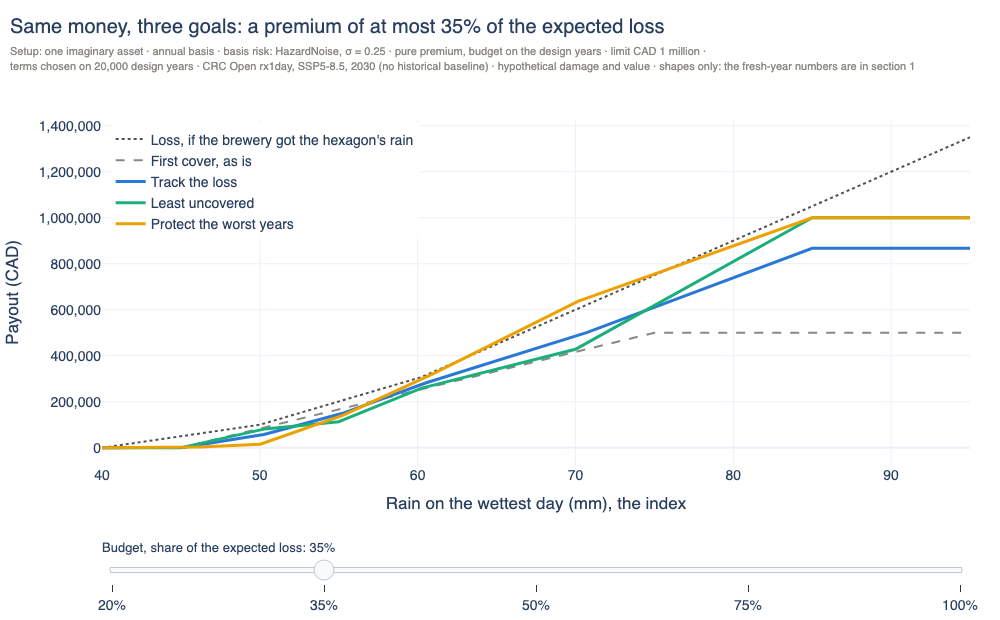

In [8]:
RATIOS = (0.2, 0.35, 0.5, 0.75, 1.0)
COLORS = dict(zip(GOALS, (BLUE, AQUA, YELLOW)))
designs = {(ratio, goal): design(template, design_years, objective, budget=Budget(ratio=ratio), limit=LIMIT)
           for ratio in RATIOS for goal, objective in GOALS.items()}

rain = np.linspace(40.0, 95.0, 221)
fig = go.Figure()
fig.add_trace(go.Scatter(x=rain, y=ASSET["value_cad"] * np.asarray(DAMAGE.evaluate(rain), dtype=float), mode="lines",
                         name="Loss, if the brewery got the hexagon's rain", line=dict(color=INK, width=2, dash="dot"),
                         hovertemplate="%{x:.0f} mm: loss CAD %{y:,.0f}<extra></extra>"))
fig.add_trace(go.Scatter(x=rain, y=first_cover.payout_values(rain), mode="lines", name="First cover, as is",
                         line=dict(color=MUTED, width=2, dash="dash"),
                         hovertemplate="First cover<br>%{x:.0f} mm: pays CAD %{y:,.0f}<extra></extra>"))
for ratio in RATIOS:
    for goal in GOALS:
        fig.add_trace(go.Scatter(x=rain, y=designs[ratio, goal].cover.payout_values(rain), mode="lines", name=goal,
                                 line=dict(color=COLORS[goal], width=3), visible=ratio == BUDGET.ratio,
                                 hovertemplate=f"{goal}<br>%{{x:.0f}} mm: pays CAD %{{y:,.0f}}<extra></extra>"))


def budget_title(ratio):
    return f"Same money, three goals: a premium of at most {ratio:.0%} of the expected loss"


steps = [dict(method="update", label=f"{ratio:.0%}",
              args=[{"visible": [True, True] + [item == ratio for item in RATIOS for _ in GOALS]},
                    {"title.text": budget_title(ratio)}])
         for ratio in RATIOS]
layout(fig, budget_title(BUDGET.ratio),
       f"Setup: one imaginary asset · annual basis · basis risk: HazardNoise, σ = {SIGMA} · pure premium, budget on the design years · "
       f"limit CAD 1 million ·<br>terms chosen on {N_YEARS:,} design years · CRC Open rx1day, SSP5-8.5, {HORIZON} (no historical baseline) · "
       f"hypothetical damage and value · shapes only: the fresh-year numbers are in section 1",
       xaxis_title="Rain on the wettest day (mm), the index", yaxis=dict(title="Payout (CAD)", tickformat=",.0f"),
       legend=dict(x=0.01, y=0.99, xanchor="left", yanchor="top", bgcolor="rgba(255,255,255,0.85)"), height=620, bottom=130,
       sliders=[dict(active=RATIOS.index(BUDGET.ratio), currentvalue=dict(prefix="Budget, share of the expected loss: ", font=dict(size=13)),
                     pad=dict(t=70), steps=steps)])
fig.show()

Read this as a description of one setup, not a ranking. The goals differ in
**which years they care about**. Tracking the loss punishes every miss, large ones
most, in both directions. Leaving the least uncovered counts only what the payout
fails to cover. The worst-years goal counts mostly the worst tenth of the years, so
on this imaginary asset, under pure pricing at this budget, it pays less around
50 mm and more around 70 mm than the other two. Yet in the section 1 table the four
covers end up close: here basis risk, more than the payout's shape, limits how much
of the loss any of them reaches.

> 💡 **Key idea: a design goal is a choice about whose bad years you care about.**
> For a payout π and a loss L, with U = max(L − π, 0) the part left uncovered:
> `MSE` minimises E[(L − π)²], `ExpectedUncovered` minimises E[U], and
> `WeightedCVaR(α, β)` minimises α·CVaR_β(U) + (1 − α)·E[U]. None of the three is
> better in general: change the site, the damage curve, the price or the budget,
> and the shapes and the numbers change with them.

## 4. In and out of sample

Every number in the section 1 table is **out of sample**: scored on fresh years,
simulated apart from the design years. Each row says so (`split`), and the module
refuses an out-of-sample number when the two sets share a year. The premium has two
bases (`premium_basis`): the designs keep the premium agreed on their design years,
and the first cover, given as is, is priced on the fresh years, so part of the small
gap between them is the gap between the years.

Why it matters: suppose the terms were chosen on just 30 years, about what a real
weather record gives. We repeat that 200 times, scoring each design on its own 30
years and on the fresh years. (This is the one place this notebook shows numbers
measured on the design years, to show what they get wrong.)

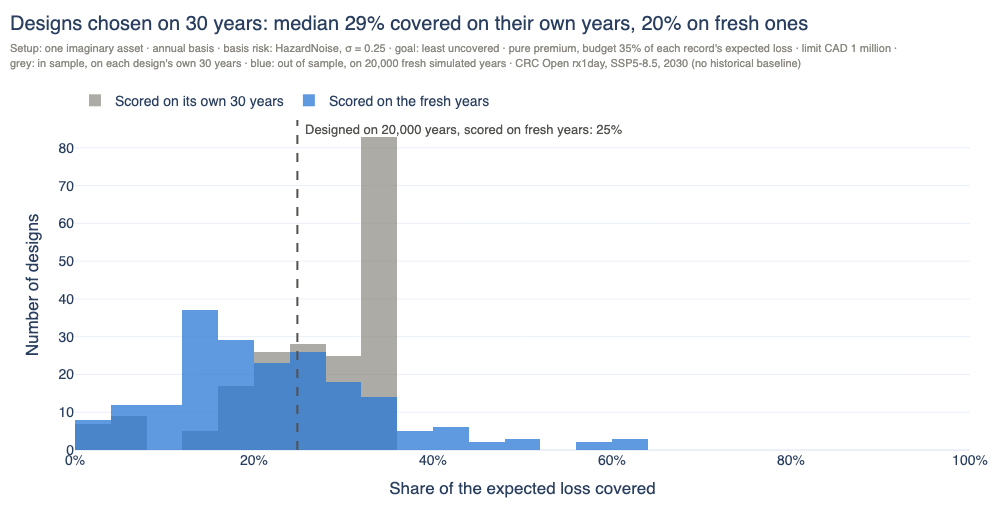

Over 200 designs chosen on 30 simulated years each, 8 in 10 cover between 8% and 36% of the expected loss on the 20,000 fresh years, and their own 30 years give no way to tell which is which.


In [9]:
REPEATS = 20 if CI else 200
SHORT = 30
own_years, fresh = [], []
for repeat in range(REPEATS):
    short_years = base.monte_carlo(SHORT, seed=1_000 + repeat).samples()[ASSET["asset_id"]]
    short_design = design(template, short_years, ExpectedUncovered(), budget=BUDGET, limit=LIMIT)
    own_years.append(evaluate(short_design, short_years, split="in_sample", options=OPTIONS)["coverage_ratio"][0].as_py())
    fresh.append(evaluate(short_design, fresh_years, split="out_of_sample", options=OPTIONS)["coverage_ratio"][0].as_py())
own_years, fresh = np.array(own_years, dtype=float), np.array(fresh, dtype=float)
long_design = rows.filter(pc.equal(rows["cover_label"], "Shape (expected_uncovered)"))["coverage_ratio"][0].as_py()

fig = go.Figure()
fig.add_trace(go.Histogram(x=own_years, xbins=dict(start=0, end=1.0001, size=0.04), name=f"Scored on its own {SHORT} years",
                           marker_color=MUTED, opacity=0.7, hovertemplate="Coverage %{x}: %{y} designs<extra></extra>"))
fig.add_trace(go.Histogram(x=fresh, xbins=dict(start=0, end=1.0001, size=0.04), name="Scored on the fresh years",
                           marker_color=BLUE, opacity=0.75, hovertemplate="Coverage %{x}: %{y} designs<extra></extra>"))
fig.add_vline(x=long_design, line=dict(color=INK, width=2, dash="dash"))
fig.add_annotation(x=long_design, y=1, yref="paper", text=f"Designed on {N_YEARS:,} years, scored on fresh years: {long_design:.0%}",
                   showarrow=False, xanchor="left", xshift=6, font=dict(color=INK, size=13))
layout(fig, f"Designs chosen on {SHORT} years: median {np.median(own_years):.0%} covered on their own years, {np.median(fresh):.0%} on fresh ones",
       f"Setup: one imaginary asset · annual basis · basis risk: HazardNoise, σ = {SIGMA} · goal: least uncovered · pure premium, "
       f"budget 35% of each record's expected loss · limit CAD 1 million ·<br>grey: in sample, on each design's own {SHORT} years · "
       f"blue: out of sample, on {N_YEARS:,} fresh simulated years · CRC Open rx1day, SSP5-8.5, {HORIZON} (no historical baseline)",
       barmode="overlay", xaxis=dict(title="Share of the expected loss covered", tickformat=".0%", range=[0, 1]),
       yaxis_title="Number of designs", legend=dict(orientation="h", yanchor="bottom", y=1.01, x=0), height=520)
fig.show()
low, high = np.percentile(fresh, [10, 90])
print(f"Over {REPEATS} designs chosen on {SHORT} simulated years each, 8 in 10 cover between {low:.0%} and {high:.0%} of the "
      f"expected loss on the {N_YEARS:,} fresh years, and their own {SHORT} years give no way to tell which is which.")

> 💡 **Key idea: test on years you did not design on.** A cover fitted to a short
> record looks better on that record than it is, and the spread between records is
> wide. With a curve, fresh years are cheap (`FreshDraws`); with a record of your
> own, hold out its latest years (`Holdout`) or each block in turn (`KFold`).

## 5. Your own years

A curve is not required. If you keep a record, one row per year with the index and
the loss, `OutcomeSample.from_table` reads it and everything above applies. Here 40
simulated years stand in for the brewery's books; the design uses the first 28, the
test the last 12:

In [10]:
loss_model = LossModel(DAMAGE, value=ASSET["value_cad"], value_unit="CAD")
curve_row = request.asset_curves().to_pylist()[0]
books = sample_curve(curve_row, metadata=metadata, n_draws=40, rng=np.random.default_rng(2024), loss_model=loss_model,
                     basis_risk=HazardNoise(SIGMA), asset_id=ASSET["asset_id"])
record = pa.table({"year": np.arange(1985, 2025), "asset_id": [ASSET["asset_id"]] * 40,
                   "rx1day": books.index[:, 0], "loss_cad": books.loss[:, 0]})   # stands in for your own table

own = OutcomeSample.from_table(record, period="year", asset_id="asset_id", index="rx1day", loss="loss_cad",
                               index_unit="mm/day", loss_unit="CAD", hazard_name="rx1day")
own_design_years, held_out = holdout(own, train_fraction=0.7)   # 1985-2012 to design, 2013-2024 to test
own_design = design(template, own_design_years, ExpectedUncovered(), budget=BUDGET, limit=LIMIT)
own_rows = compare([first_cover, own_design], held_out, split="out_of_sample", design_sample=own_design_years, options=OPTIONS)
show(own_rows)
print(setup_text(own_rows))

,Premium basis,Premium (CAD),Expected loss (CAD),Expected loss covered,"Loss covered, worst 10% of years",Loss years with no payout,No-loss years with a payout
cover_label,,,,,,,
First cover,evaluation,"26,902","110,514",20.4%,6.8%,33.3%,11.1%
Shape,design,"16,170","110,514",8.1%,3.6%,66.7%,0.0%


Level: asset (Wet Basement Brewing). Scenario: baseline. Basis: annual, one draw is one year.
Split: out of sample, fold 0, a holdout with train fraction 0.7: evaluated on 12 years (periods 2013 to 2024), the held-out block; designed on 28 years (periods 1985 to 2012), the design block; the leakage check passed: the two share no period of one source.
Sample: rows of a user table, each a year as the caller states. Basis risk: not modelled; the index and the loss are used as given. Loss: from the table, in CAD.
Source: the table, with provider, dataset, horizon and pathway not recorded.
Pricing: the pure premium, P = E[payout], on the evaluation sample, for the covers given as is; a design keeps its design premium, and premium_basis says which premium a row uses.
Design Shape (474c89dc1b02): objective: E[U], the expected uncovered loss; pricing: the pure premium, P = E[payout]; budget: premium at most 0.35 x E[L] of the design sample; limit: 1,000,000 CAD; design premium: 16,170.2 CAD; r

Twelve held-out years are few, so these numbers move a lot from one record to the
next (section 4). If your record has the hazard but not the loss, such as ERA5's or
a station's wettest days, `sample_annual` adds the loss from your damage curve and a
basis-risk model, and `ParametricPlan.for_annual_extremes` runs the same plan on
such tables. The [guide](https://github.com/marc272/crc-sdk/blob/parametric/docs/parametric.md#next-step-per-year-values) shows both.

In [11]:
series = AnnualSeries.from_table(record, value="rx1day", unit="mm/day", source="the brewery's books")
print(sample_annual(series, loss_model=loss_model, basis_risk=HazardNoise(SIGMA), asset_id=ASSET["asset_id"],
                    rng=np.random.default_rng(3), hazard_name="rx1day"))

OutcomeSample(shape=(40, 1), assets=['Wet Basement Brewing'], hazard_name='rx1day', index_unit='mm/day', loss_unit='CAD', semantics='annual', scenario='baseline', content_hash='sha256:7a5d8ce434af...')


## 6. The functions underneath, and saving a comparison

The plan is a chain of functions you can call yourself, with no I/O:
`sample_curve`, `design`, `compare`. Given the generator the plan gives its first
asset, `sample_curve` draws the same years, and a design by hand is the plan's own,
with the same id. `write_comparison` saves a table, and the file keeps its setup:

In [12]:
def draws(seed):
    rng = np.random.default_rng(np.random.SeedSequence(seed).spawn(1)[0])   # the plan's generator for its first asset
    return sample_curve(curve_row, metadata=metadata, n_draws=N_YEARS, rng=rng, loss_model=loss_model,
                        basis_risk=HazardNoise(SIGMA), asset_id=ASSET["asset_id"])


by_hand, by_hand_fresh = draws(42), draws(7)
tail_design = design(template, by_hand, GOALS["Protect the worst years"], budget=BUDGET, limit=LIMIT)
table = compare([first_cover, tail_design], by_hand_fresh, split="out_of_sample", design_sample=by_hand, options=OPTIONS)
write_comparison(table, DATA / "by-hand.parquet")   # one Parquet file, written atomically

print("The plan's years:", by_hand.content_hash == design_years.content_hash and by_hand_fresh.content_hash == fresh_years.content_hash)
print("The plan's design:", tail_design.design_id == result.designs[2].design_id)
print("The same setup, read back from the file:", setup_text(pq.read_table(DATA / "by-hand.parquet")) == setup_text(table))
print()
print(tail_design.cover.terms_text())

The plan's years: True
The plan's design: True
The same setup, read back from the file: True

Label: Shape (a display name, not part of the terms)
Asset: Wet Basement Brewing
Index: rx1day, in mm/day, read at the asset; larger values are more severe (tail upper); aggregation: annual_maximum; source: not stated
Payout per year, in CAD: straight lines between knots, the levels never decrease (kind "piecewise_linear", monotone=True)
  - nothing when rx1day is below 45 mm/day
  - in a straight line from 0 CAD at 45 mm/day to 14,898.99769240946 CAD at 50 mm/day
  - in a straight line from 14,898.99769240946 CAD at 50 mm/day to 133,256.6144430376 CAD at 55 mm/day
  - in a straight line from 133,256.6144430376 CAD at 55 mm/day to 288,168.53028953297 CAD at 60 mm/day
  - in a straight line from 288,168.53028953297 CAD at 60 mm/day to 633,137.7044539457 CAD at 70 mm/day
  - in a straight line from 633,137.7044539457 CAD at 70 mm/day to 1,000,000 CAD at 85 mm/day
  - 1,000,000 CAD when rx1day is

The last lines are the designed cover's **terms in words**, for a report or a
broker: every amount as the contract holds it, and the hash that identifies it. A
rounded amount is another contract, with another hash.

## Where next

- Short showcases, one question each, are coming.
- The module's [full guide](https://github.com/marc272/crc-sdk/blob/parametric/docs/parametric.md) covers the rest: other payout families,
  loaded pricing, several assets, several hazards and scenarios.
- Change σ, the budget or a goal above and rerun.

*An illustration of a method, not insurance advice or a price.*

*The weighted-CVaR goal comes from Marc Prinzing's master's thesis,
"Tail-Risk Optimized Payout Design in Parametric Insurance".*

*Data: CRC Open by Riskthinking.AI (CC BY-NC 4.0; SSP5-8.5 only, no historical
baseline).*